<div class="alert alert-info" role="alert"
     style="font-size: 1.55em; font-weight: bold; padding: 15px; margin: 10px 0; text-align: left; background-color: #d9edf7; border-color: #bce8f1; color: #31708f; border-radius: 8px;">
    AVHRR equator-crossing local times, 1990-2026
</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Use Roboto Font because autism apparently
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Regular.ttf")
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Bold.ttf")
plt.rcParams["font.weight"] = "normal"
plt.rcParams["axes.titleweight"] = "bold"

cross = pd.read_csv("/home/nandii/cloudML/avhrr_crossing_times_1990_2026.csv", parse_dates = ["date"], low_memory = False)

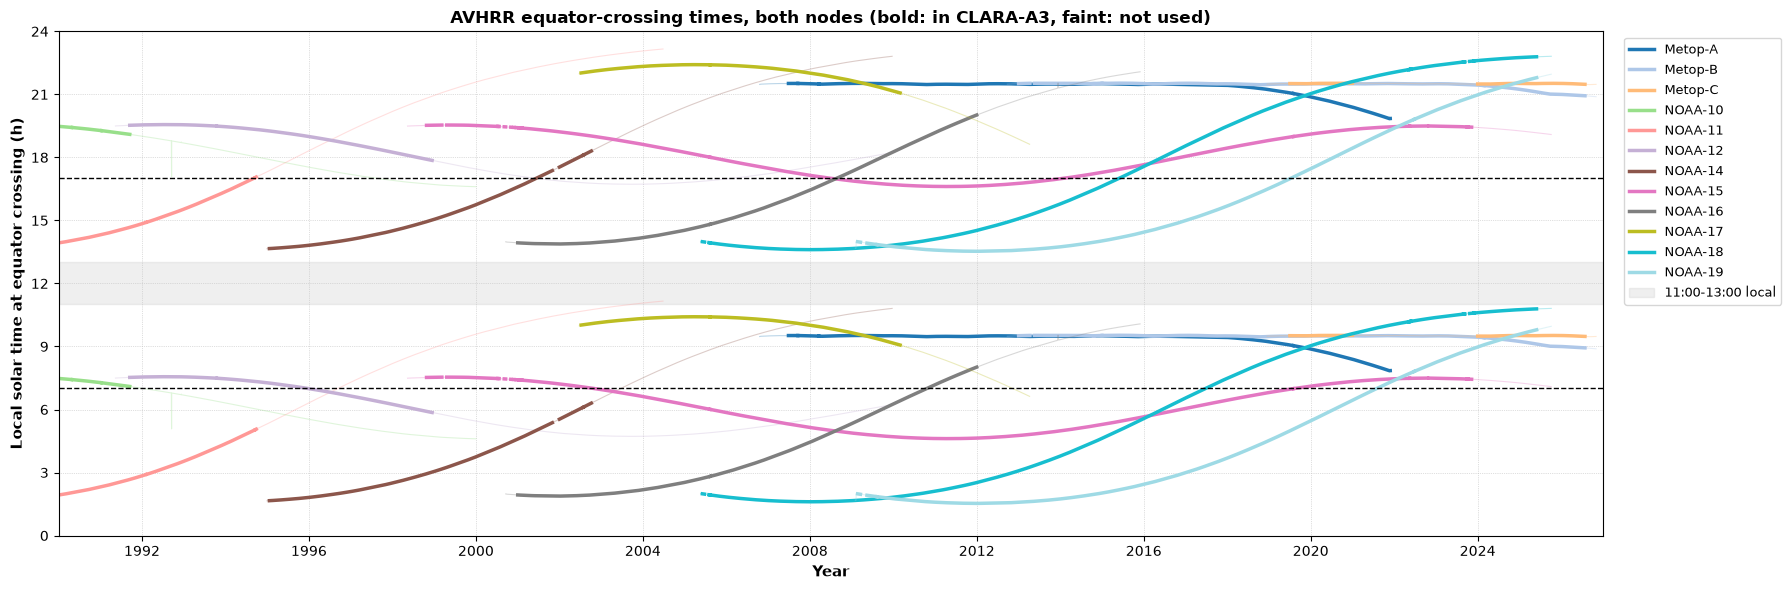

In [2]:
fig, ax = plt.subplots(figsize = (18, 6))
colours = dict(zip(sorted(cross["satellite"].unique()), plt.cm.tab20(np.linspace(0, 1, cross["satellite"].nunique()))))

for sat, g in cross.dropna(subset = ["asc_local_h"]).groupby("satellite"):
    g = g.set_index("date").sort_index()
    for node in ["asc_local_h", "desc_local_h"]:
        # Break the line where it wraps past midnight
        y = g[node].where(g[node].diff().abs().fillna(0) < 12)
        ax.plot(g.index, y, color = colours[sat], linewidth = 0.8, alpha = 0.3)
        ax.plot(g.index, y.where(g["in_clara"]), color = colours[sat], linewidth = 2.5,
                label = sat if node == "asc_local_h" else None)

ax.axhspan(11, 13, color = "silver", alpha = 0.25, label = "11:00-13:00 local")
for h in [7, 17]:
    ax.axhline(h, color = "black", linestyle = "--", linewidth = 1)
ax.set_ylim(0, 24)
ax.set_yticks(range(0, 25, 3))
ax.set_xlim(pd.Timestamp("1990-01-01"), pd.Timestamp("2026-12-31"))
ax.set_xlabel("Year", fontsize = 11, weight = "bold")
ax.set_ylabel("Local solar time at equator crossing (h)", fontsize = 11, weight = "bold")
ax.set_title("AVHRR equator-crossing times, both nodes (bold: in CLARA-A3, faint: not used)", fontsize = 12, weight = "bold")
ax.grid(True, color = "silver", linestyle = ":", linewidth = 0.5)
ax.legend(loc = "upper left", bbox_to_anchor = (1.01, 1), fontsize = 9)
plt.tight_layout()
plt.show()

fig.savefig("AVHRR_crossing_times_1990_2026.png", dpi = 300, bbox_inches = "tight")